# Portefeuille multi-actifs — Amérique du Nord
**Python pour la Data Science — Projet final**

Investisseur européen (par exemple un assureur) : toutes les valeurs sont exprimées en **euros**.
Portefeuille de 5 ETF cotés aux États-Unis : SPY, QQQ, IWM, EWC, VNQ.
Données quotidiennes Yahoo Finance, du 02/01/2015 au 20/11/2026.

*Actifs choisis à des fins pédagogiques, pas de recommandation d'investissement.*


In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Racine du projet : le notebook s'exécute depuis "notebooks/", on remonte d'un niveau
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# On ajoute la racine au chemin de recherche de Python pour pouvoir importer "src"
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

# Fonctions écrites dans src/ (on les réutilise au lieu de les réécrire)
from src.analysis import (load_prices, compute_returns, rolling_volatility, drawdown,
                          portfolio_returns, portfolio_value, stats_table,
                          portfolios_comparison, WEIGHTS_EQUAL, WEIGHTS_ALT, TRADING_DAYS)
from src.risk import (simulate_bootstrap_vec, simulate_normal_vec, risk_metrics,
                      compare_loop_vs_vec, run_all, N_SCENARIOS, HORIZON, INITIAL, LEVEL)

CAPITAL = 100_000                      # capital initial fictif, en euros
plt.rcParams["figure.figsize"] = (12, 5)

print("Racine du projet :", RACINE)

Matplotlib is building the font cache; this may take a moment.


Racine du projet : c:\Users\awflo\projet-final-python-portefeuille-multi-actifs-var-asie-pacifique


## 1. Les données
Prix de clôture **ajustés** (dividendes et divisions d'actions inclus), en dollars,
convertis en euros avec le taux EUR/USD (nombre de dollars pour 1 euro) :
**prix en € = prix en $ / EURUSD**.
Les jours où le taux manque sur un jour de bourse américaine, on reprend le dernier taux connu.

In [3]:
prix_usd = pd.read_csv(RACINE / "data" / "raw" / "prix_etf_usd.csv", index_col="Date", parse_dates=True)
taux = pd.read_csv(RACINE / "data" / "raw" / "taux_eurusd.csv", index_col="Date", parse_dates=True)["EURUSD=X"]
prix_eur = load_prices()

print(f"{len(prix_eur)} séances, du {prix_eur.index[0].date()} au {prix_eur.index[-1].date()}")
print("Valeurs manquantes :", int(prix_eur.isna().sum().sum()))
print("Dates triées       :", prix_eur.index.is_monotonic_increasing)
print("Prix tous positifs :", bool((prix_eur > 0).all().all()))
prix_eur.tail()

2990 séances, du 2015-01-02 au 2026-11-20
Valeurs manquantes : 0
Dates triées       : True
Prix tous positifs : True


,SPY,QQQ,IWM,EWC,VNQ
Date,,,,,
2026-11-16,671.164262,600.233723,247.567501,53.751189,87.284463
2026-11-17,665.963729,597.325212,244.631004,53.363293,86.277781
2026-11-18,664.248367,599.943083,245.722764,52.070086,86.583345
2026-11-19,652.451031,587.895850,240.812736,51.266809,85.189488
2026-11-20,628.830800,554.663036,233.925665,50.037724,84.377695


In [5]:
# On refait la conversion à partir des données brutes et on compare au fichier préparé
taux_aligne = taux.reindex(prix_usd.index).ffill()
prix_eur_recalcule = prix_usd.div(taux_aligne, axis=0)
ecart_max = (prix_eur_recalcule - prix_eur).abs().max().max()
print(f"Écart maximal entre conversion recalculée et fichier : {ecart_max:.2e} €")

Écart maximal entre conversion recalculée et fichier : 0.00e+00 €


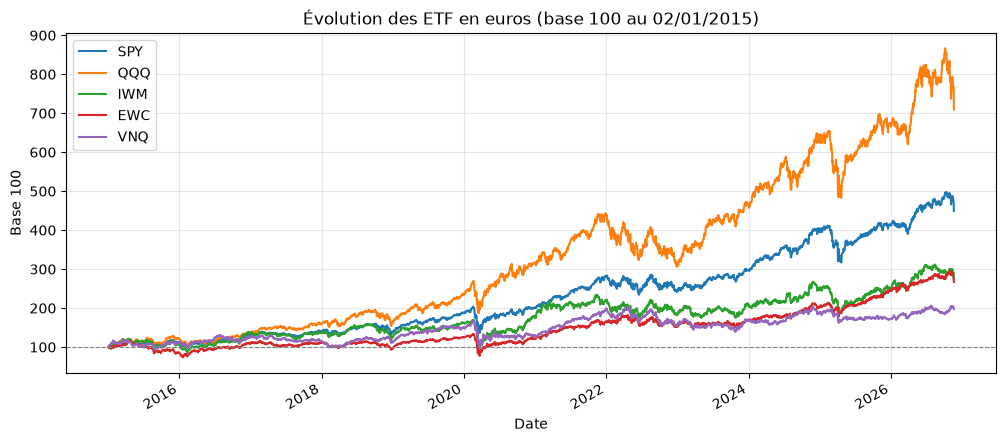

Valeur finale pour 100 € investis au départ :
QQQ    709.9
SPY    449.1
IWM    276.5
EWC    267.0
VNQ    197.5
Name: 2026-11-20 00:00:00, dtype: float64


In [6]:
base100 = prix_eur / prix_eur.iloc[0] * 100

fig, ax = plt.subplots()
base100.plot(ax=ax)
ax.axhline(100, color="grey", lw=0.8, ls="--")
ax.set_title("Évolution des ETF en euros (base 100 au 02/01/2015)")
ax.set_ylabel("Base 100")
ax.grid(alpha=0.3)
plt.show()

print("Valeur finale pour 100 € investis au départ :")
print(base100.iloc[-1].round(1).sort_values(ascending=False))

In [ ]:
# La baisse de fin de période vient-elle des marchés ou du change ?
derniers_jours = pd.DataFrame({
    "SPY en $": prix_usd["SPY"],
    "QQQ en $": prix_usd["QQQ"],
    "EUR/USD": taux_aligne,
    "SPY en €": prix_eur["SPY"],
}).tail(6)

print("Niveaux :")
print(derniers_jours.round(4))
print("\nVariations quotidiennes (%) :")
print((derniers_jours.pct_change() * 100).round(2))

Niveaux :
            SPY en $  QQQ en $  EUR/USD  SPY en €
Date                                             
2026-11-13    754.37    679.89   1.1050  682.6747
2026-11-16    739.95    661.75   1.1025  671.1643
2026-11-17    732.44    656.95   1.0998  665.9637
2026-11-18    730.20    659.51   1.0993  664.2484
2026-11-19    715.87    645.04   1.0972  652.4510
2026-11-20    689.81    608.45   1.0970  628.8308

Variations quotidiennes (%) :
            SPY en $  QQQ en $  EUR/USD  SPY en €
Date                                             
2026-11-13       NaN       NaN      NaN       NaN
2026-11-16     -1.91     -2.67    -0.23     -1.69
2026-11-17     -1.01     -0.73    -0.24     -0.77
2026-11-18     -0.31      0.39    -0.05     -0.26
2026-11-19     -1.96     -2.19    -0.19     -1.78
2026-11-20     -3.64     -5.67    -0.02     -3.62


### Interprétation des données
- **Qualité** : 2 990 séances du 02/01/2015 au 20/11/2026 (près de 12 ans), aucune valeur manquante,
  dates triées, prix tous positifs. La conversion en euros, recalculée à partir des données brutes,
  donne un écart nul avec le fichier préparé.
- **Performances** : pour 100 € investis au départ, on obtient 709,9 € avec QQQ (× 7,1), 449,1 € avec SPY,
  276,5 € avec IWM, 267,0 € avec EWC et 197,5 € avec VNQ. Les grandes valeurs technologiques (QQQ)
  ont nettement dominé ; l'immobilier coté (VNQ) a le moins progressé.
- **Épisodes de crise visibles** : krach de mars 2020, baisse de 2022 (très marquée sur QQQ),
  chute début 2025.
- **Fin de période** : la dernière semaine (13 → 20/11/2026) est une forte baisse : SPY −8,6 % en dollars,
  dont −3,6 % sur la seule séance du 20/11. La décomposition montre qu'il s'agit d'une baisse des marchés
  américains et non d'un effet de change (EUR/USD quasi stable ce jour-là). En euros, la baisse est
  légèrement amortie (−7,9 %) car l'euro a un peu reculé face au dollar.

## 2. Analyse descriptive
Indicateurs calculés pour chaque ETF à partir des prix en euros :
rendements, volatilité (globale et glissante), drawdown (perte depuis le plus haut) et corrélations.
Convention : 252 jours de cotation par an.

(2989, 5)


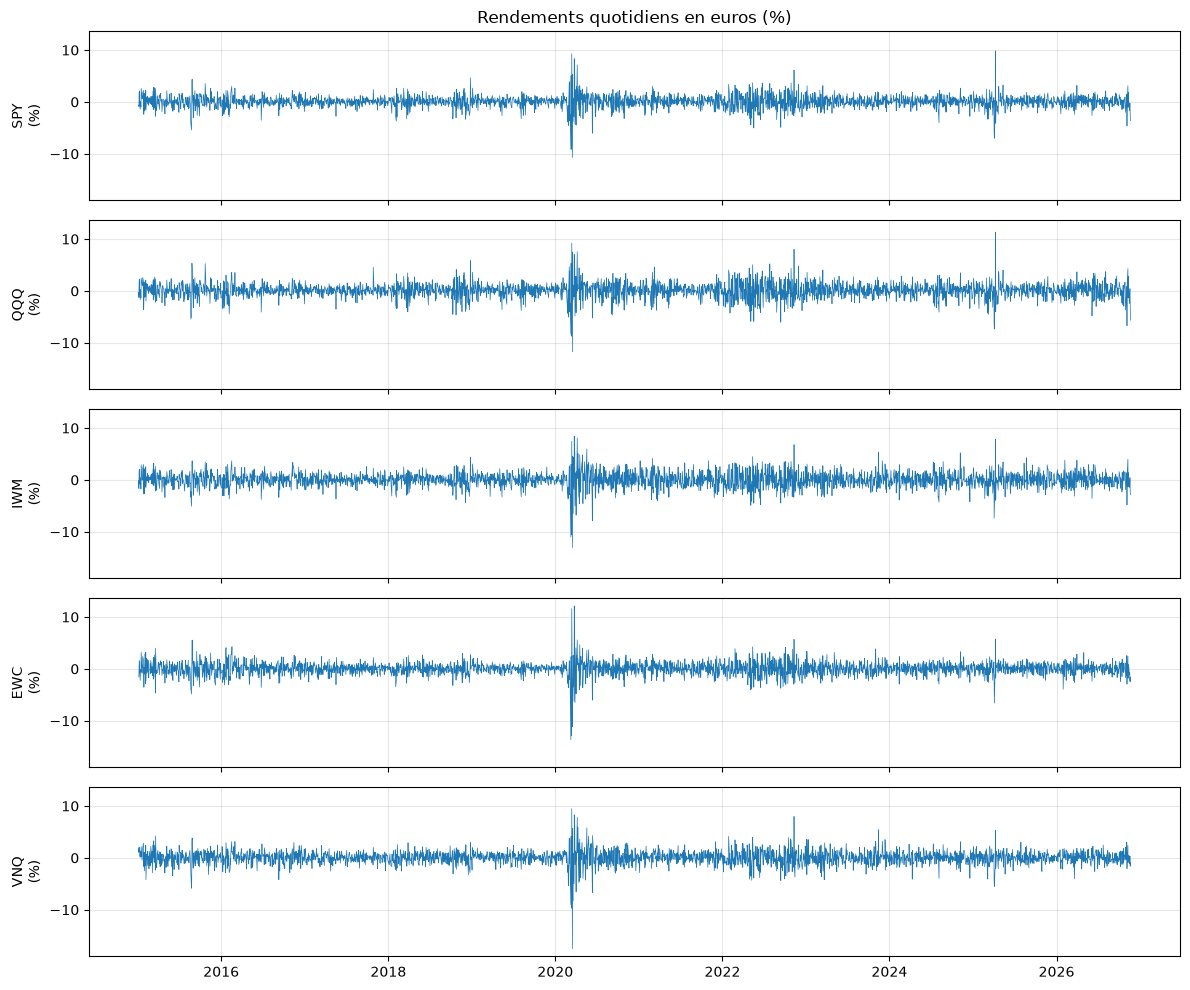

In [8]:
rendements = compute_returns(prix_eur)   # prix(t) / prix(t-1) - 1, première ligne supprimée
print(rendements.shape)

fig, axes = plt.subplots(len(rendements.columns), 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, ticker in zip(axes, rendements.columns):
    ax.plot(rendements.index, rendements[ticker] * 100, lw=0.5)
    ax.set_ylabel(f"{ticker}\n(%)")
    ax.grid(alpha=0.3)
axes[0].set_title("Rendements quotidiens en euros (%)")
plt.tight_layout()
plt.show()

In [9]:
stats = stats_table(rendements)                        # fonctions de src/analysis.py
stats.insert(0, "Rendement cumulé", (1 + rendements).prod() - 1)
stats.insert(2, "Volatilité quotidienne", rendements.std())

stats.style.format("{:.2%}")

,Rendement cumulé,Rendement annualisé,Volatilité quotidienne,Volatilité annualisée,Perte maximale
SPY,349.12%,13.50%,1.20%,19.11%,-33.09%
QQQ,609.86%,17.97%,1.47%,23.33%,-30.87%
IWM,176.51%,8.95%,1.48%,23.52%,-41.88%
EWC,166.96%,8.63%,1.29%,20.47%,-42.12%
VNQ,97.53%,5.91%,1.35%,21.47%,-41.89%


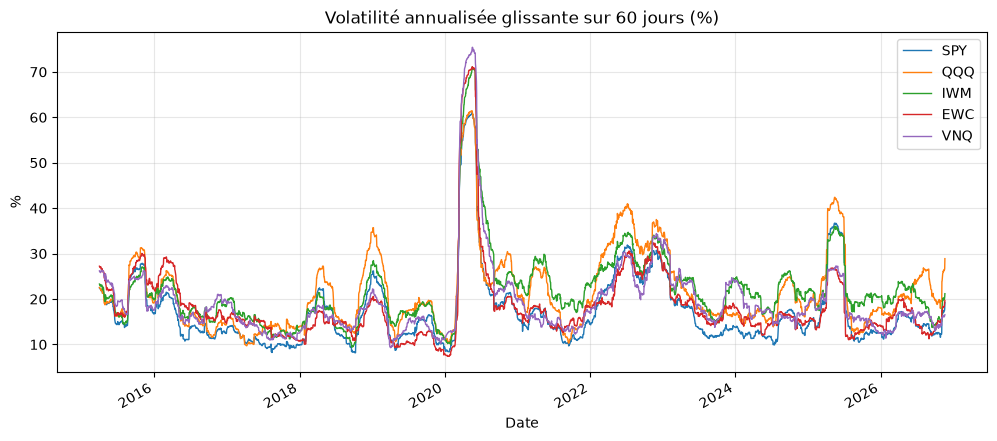

In [10]:
vol_glissante = rolling_volatility(rendements, window=60)   # écart-type sur 60 jours x racine(252)

fig, ax = plt.subplots()
(vol_glissante * 100).plot(ax=ax, lw=1)
ax.set_title("Volatilité annualisée glissante sur 60 jours (%)")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
plt.show()

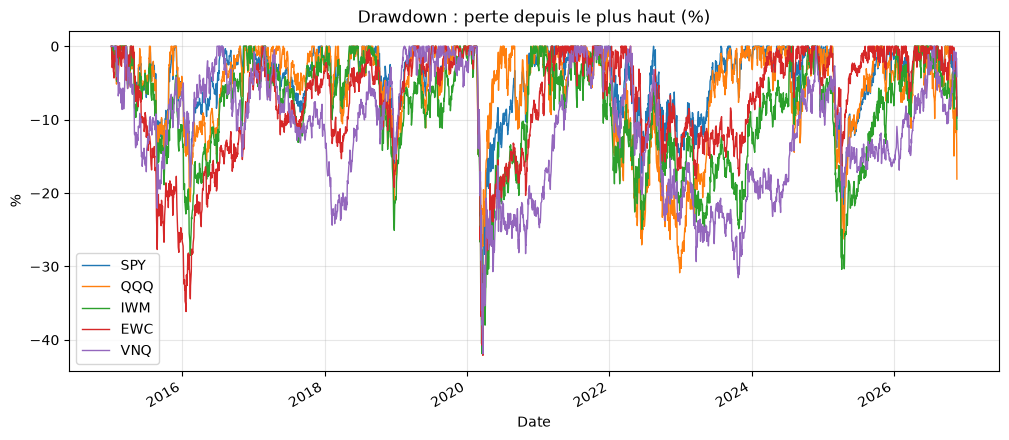

Pire drawdown de chaque ETF :
    Perte maximale        Date
SPY        -33.1 %  2020-03-23
QQQ        -30.9 %  2022-12-28
IWM        -41.9 %  2020-03-18
EWC        -42.1 %  2020-03-23
VNQ        -41.9 %  2020-03-23


In [11]:
dd = drawdown(prix_eur)        # prix / plus haut historique - 1

fig, ax = plt.subplots()
(dd * 100).plot(ax=ax, lw=1)
ax.set_title("Drawdown : perte depuis le plus haut (%)")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
plt.show()

print("Pire drawdown de chaque ETF :")
print(pd.DataFrame({"Perte maximale": (dd.min() * 100).round(1).astype(str) + " %",
                    "Date": dd.idxmin().dt.date}))

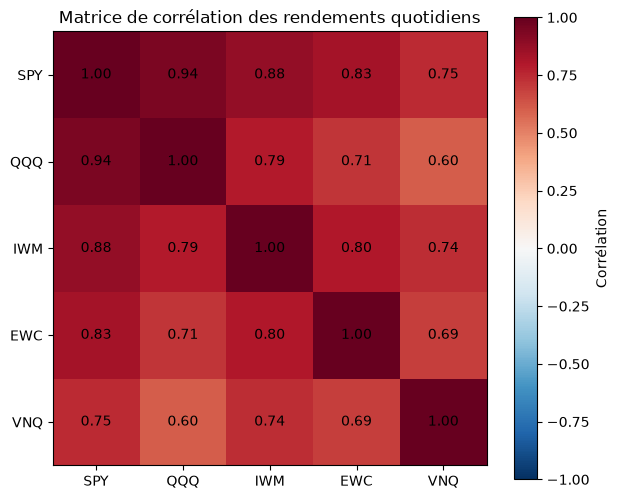

In [12]:
correlations = rendements.corr()

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations)), correlations.columns)
ax.set_yticks(range(len(correlations)), correlations.columns)
for i in range(len(correlations)):            # on écrit la valeur dans chaque case
    for j in range(len(correlations)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Corrélation")
ax.set_title("Matrice de corrélation des rendements quotidiens")
plt.show()

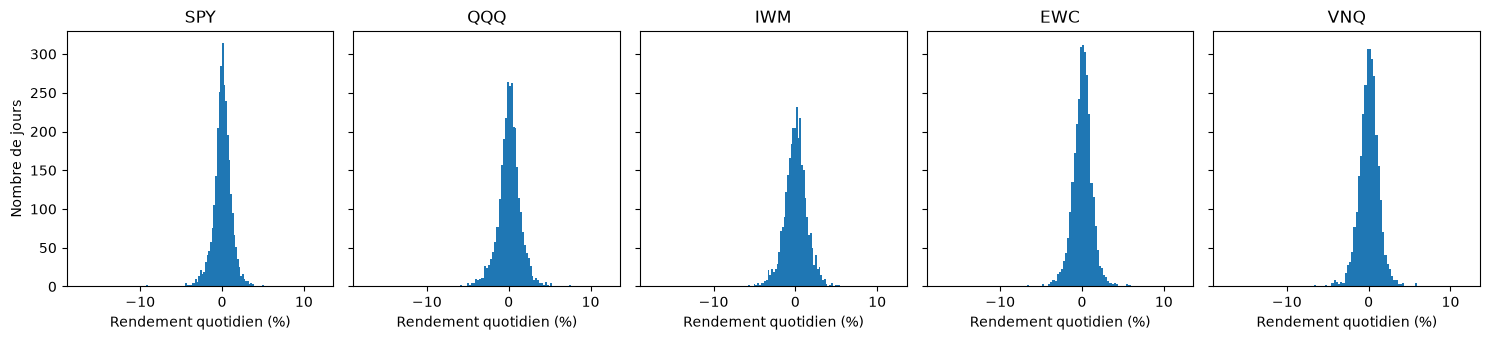

In [13]:
fig, axes = plt.subplots(1, len(rendements.columns), figsize=(15, 3.5), sharex=True, sharey=True)
for ax, ticker in zip(axes, rendements.columns):
    ax.hist(rendements[ticker] * 100, bins=100)
    ax.set_title(ticker)
    ax.set_xlabel("Rendement quotidien (%)")
axes[0].set_ylabel("Nombre de jours")
plt.tight_layout()
plt.show()

### Interprétation de l'analyse descriptive
- **Rendement et risque** : QQQ offre le meilleur rendement annualisé (17,97 %) pour une volatilité
  de 23,33 %, suivi de SPY (13,50 % pour 19,11 %). IWM a une volatilité équivalente à celle de QQQ
  (23,52 %) pour un rendement deux fois plus faible (8,95 %) : plus de risque n'a pas toujours été
  mieux rémunéré. VNQ est le moins rentable (5,91 %).
- **Pertes maximales** : quatre ETF ont connu leur pire chute lors du krach Covid de mars 2020 :
  EWC −42,1 %, IWM −41,9 % et VNQ −41,9 % (point bas entre le 18 et le 23/03/2020), SPY −33,1 %.
  QQQ fait exception : sa pire chute (−30,9 %) date du 28/12/2022, au terme d'une année de forte
  hausse des taux d'intérêt, particulièrement défavorable aux valeurs technologiques.
- **Volatilité glissante** : le risque varie fortement dans le temps, de 10–15 % en période calme
  à plus de 70 % en mars 2020, avec d'autres pics en 2022 et début 2025.
- **Corrélations** : toutes élevées (0,60 à 0,94). SPY et QQQ sont presque identiques (0,94),
  car ils détiennent les mêmes grandes entreprises. L'immobilier (VNQ) est le meilleur diversifiant
  (0,60 avec QQQ). La conversion en euros ajoute en plus un facteur de change commun aux 5 ETF :
  la diversification de ce panier est limitée.
- **Distribution** : les rendements quotidiens sont concentrés autour de 0 mais présentent des jours
  extrêmes (±10 %) plus fréquents que ne le prévoirait une loi normale (« queues épaisses »).

## 3. Les portefeuilles
Deux répartitions sont comparées, avec un capital initial fictif de **100 000 €** :
- **Poids égaux** : 20 % sur chaque ETF ;
- **Répartition alternative** : 40 % SPY, 10 % QQQ, 10 % IWM, 20 % EWC, 20 % VNQ.

**Convention** : rééquilibrage quotidien, c'est-à-dire que les poids sont remis à leur valeur cible
chaque jour. Le rendement du portefeuille un jour donné est alors la somme pondérée des rendements
des ETF : $r_{p,t} = \sum_i w_i \, r_{i,t}$.

In [14]:
poids = pd.DataFrame({"Poids égaux": WEIGHTS_EQUAL, "Répartition alternative": WEIGHTS_ALT})
print("Somme des poids :", poids.sum().to_dict())
poids.style.format("{:.0%}")

Somme des poids : {'Poids égaux': 1.0, 'Répartition alternative': 1.0}


,Poids égaux,Répartition alternative
SPY,20%,40%
QQQ,20%,10%
IWM,20%,10%
EWC,20%,20%
VNQ,20%,20%


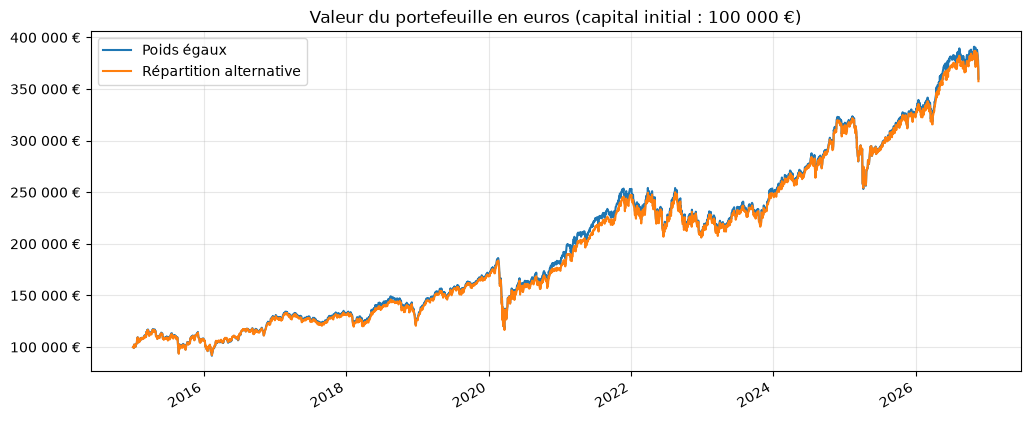

,Poids égaux,Répartition alternative
2015-01-02 00:00:00,"100,000 €","100,000 €"
2026-11-20 00:00:00,"359,963 €","357,569 €"


In [15]:
valeurs = pd.DataFrame({
    "Poids égaux": portfolio_value(rendements, WEIGHTS_EQUAL, initial=CAPITAL),
    "Répartition alternative": portfolio_value(rendements, WEIGHTS_ALT, initial=CAPITAL),
})
# On ajoute le jour de départ (100 000 €), absent des rendements
depart = pd.DataFrame(CAPITAL, index=[prix_eur.index[0]], columns=valeurs.columns)
valeurs = pd.concat([depart, valeurs])

fig, ax = plt.subplots()
valeurs.plot(ax=ax)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f} €".replace(",", " ")))
ax.set_title(f"Valeur du portefeuille en euros (capital initial : {CAPITAL:,} €)".replace(",", " "))
ax.grid(alpha=0.3)
plt.show()

valeurs.iloc[[0, -1]].style.format("{:,.0f} €")

In [16]:
comparaison = portfolios_comparison(rendements)          # fonction de src/analysis.py
comparaison.insert(0, "Valeur finale (€)", valeurs.iloc[-1])
comparaison.style.format({"Valeur finale (€)": "{:,.0f} €",
                          "Rendement annualisé": "{:.2%}",
                          "Volatilité annualisée": "{:.2%}",
                          "Perte maximale": "{:.2%}"})

,Valeur finale (€),Rendement annualisé,Volatilité annualisée,Perte maximale
Poids égaux,"359,963 €",11.40%,19.50%,-36.79%
Répartition alternative,"357,569 €",11.34%,18.96%,-36.64%


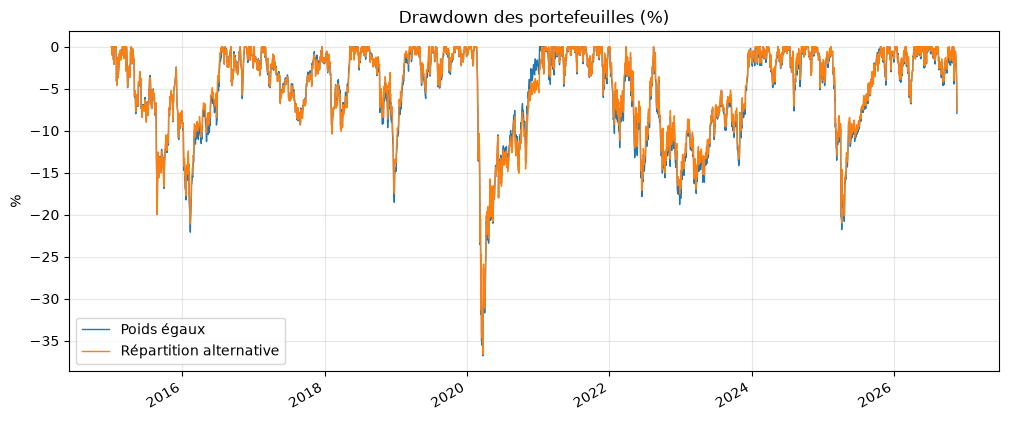

In [17]:
dd_portefeuilles = drawdown(valeurs)

fig, ax = plt.subplots()
(dd_portefeuilles * 100).plot(ax=ax, lw=1)
ax.set_title("Drawdown des portefeuilles (%)")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
plt.show()

In [18]:
# Buy-and-hold : on achète 20 % de chaque ETF au départ, puis on ne touche plus à rien
w = pd.Series(WEIGHTS_EQUAL)
buy_and_hold = CAPITAL * (prix_eur / prix_eur.iloc[0]).mul(w, axis=1).sum(axis=1)

pd.DataFrame({
    "Rééquilibrage quotidien": valeurs["Poids égaux"],
    "Buy-and-hold": buy_and_hold,
}).iloc[-1].to_frame("Valeur finale (€)").style.format("{:,.0f} €")

,Valeur finale (€)
Rééquilibrage quotidien,"359,963 €"
Buy-and-hold,"379,996 €"


- **Pertes maximales** : quatre ETF ont connu leur pire chute lors du krach Covid de mars 2020 :
  EWC −42,1 %, IWM −41,9 % et VNQ −41,9 % (point bas entre le 18 et le 23/03/2020), SPY −33,1 %.
  QQQ fait exception : sa pire chute (−30,9 %) date du 28/12/2022, au terme d'une année de forte
  hausse des taux d'intérêt, particulièrement défavorable aux valeurs technologiques.

## 4. Simulation du risque à un an
Objectif : estimer la distribution de la valeur du portefeuille dans **un an (252 jours de cotation)**
à partir de **100 000 scénarios**, puis en déduire la **VaR à 99,5 %** et l'**Expected Shortfall**.

**Convention** : perte = valeur initiale − valeur finale (positive en cas de perte).
- **VaR 99,5 %** : perte dépassée dans seulement 0,5 % des scénarios (quantile à 99,5 % des pertes).
- **Expected Shortfall 99,5 %** : perte moyenne dans ces 0,5 % pires scénarios.

**Méthodes** :
1. *Bootstrap historique* : 252 jours tirés au hasard (avec remise) parmi les rendements passés
   du portefeuille. Les rendements d'un même jour étant tirés ensemble, la dépendance entre ETF
   est conservée.
2. *Loi normale* : 252 rendements tirés dans une loi normale de même moyenne et même écart-type
   que les rendements historiques du portefeuille.

Chaque méthode est codée en deux versions (boucles Python et NumPy vectorisé). Graine aléatoire fixe
(42) pour des résultats reproductibles.

In [19]:
rend_portefeuilles = {
    "Poids égaux": portfolio_returns(rendements, WEIGHTS_EQUAL),
    "Répartition alternative": portfolio_returns(rendements, WEIGHTS_ALT),
}
print(f"Horizon : {HORIZON} jours | Scénarios : {N_SCENARIOS:,} | Niveau : {LEVEL:.1%}".replace(",", " "))
print(f"Nombre de jours historiques disponibles pour le bootstrap : {len(rend_portefeuilles['Poids égaux'])}")

Horizon : 252 jours | Scénarios : 100 000 | Niveau : 99.5%
Nombre de jours historiques disponibles pour le bootstrap : 2989


In [20]:
from src.risk import CHUNK

# Comparaison sur le même nombre de scénarios (100 000) : résultats et durées
comparaison_vitesse = compare_loop_vs_vec(rend_portefeuilles["Poids égaux"], n_compare=N_SCENARIOS)

# Mémoire occupée par le tableau des tirages (8 octets par nombre décimal)
comparaison_vitesse["Mémoire d'un bloc NumPy (Mo)"] = CHUNK * HORIZON * 8 / 1e6
comparaison_vitesse["Mémoire sans blocs (Mo)"] = N_SCENARIOS * HORIZON * 8 / 1e6

comparaison_vitesse.T.round(3)

Méthode,bootstrap,normale
Scénarios,100000.000,100000.000
VaR boucles (%),0.338,0.325
VaR NumPy (%),0.334,0.324
Durée boucles (s),7.480,7.215
Durée NumPy (s),0.427,0.462
Rapport de vitesse,17.515,15.625
Mémoire d'un bloc NumPy (Mo),20.160,20.160
Mémoire sans blocs (Mo),201.600,201.600


In [21]:
essai_1 = simulate_bootstrap_vec(rend_portefeuilles["Poids égaux"], N_SCENARIOS)
essai_2 = simulate_bootstrap_vec(rend_portefeuilles["Poids égaux"], N_SCENARIOS)
print("Deux exécutions donnent exactement les mêmes scénarios :", np.array_equal(essai_1, essai_2))
print("Forme du tableau des valeurs finales :", essai_1.shape)

Deux exécutions donnent exactement les mêmes scénarios : True
Forme du tableau des valeurs finales : (100000,)


In [22]:
resultats = run_all(rend_portefeuilles)          # versions NumPy, 100 000 scénarios

# Calculs faits pour 100 € : on les ramène au capital de 100 000 €
resultats["VaR (€ pour 100 000 €)"] = resultats["VaR 99,5 % (%)"] * CAPITAL
resultats["ES (€ pour 100 000 €)"] = resultats["Expected Shortfall (%)"] * CAPITAL

resultats[["VaR 99,5 % (%)", "Expected Shortfall (%)",
           "VaR (€ pour 100 000 €)", "ES (€ pour 100 000 €)"]].style.format({
    "VaR 99,5 % (%)": "{:.2%}", "Expected Shortfall (%)": "{:.2%}",
    "VaR (€ pour 100 000 €)": "{:,.0f} €", "ES (€ pour 100 000 €)": "{:,.0f} €"})

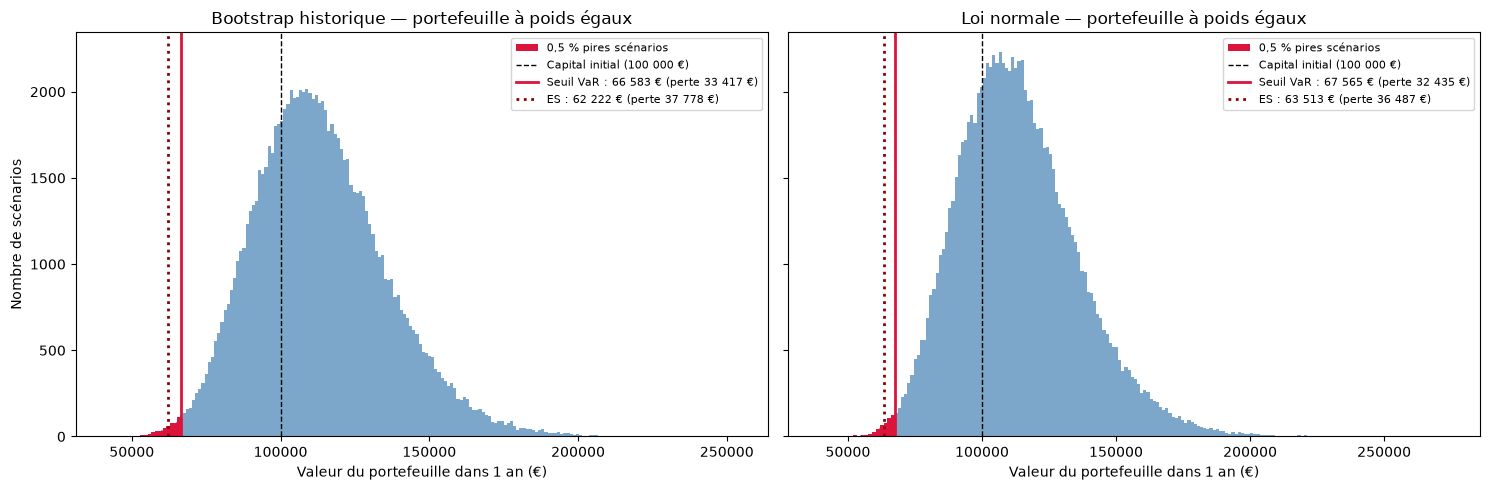

: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
methodes = [("Bootstrap historique", simulate_bootstrap_vec), ("Loi normale", simulate_normal_vec)]

for ax, (nom, fonction) in zip(axes, methodes):
    # Valeurs finales pour un capital de 100 000 € (la simulation est faite pour 100 €)
    finales = fonction(rend_portefeuilles["Poids égaux"], N_SCENARIOS) * CAPITAL / INITIAL
    m = risk_metrics(finales, initial=CAPITAL)
    seuil_var = CAPITAL - m["VaR 99,5 % (€)"]               # valeur finale au seuil de la VaR
    moyenne_pires = CAPITAL - m["Expected Shortfall (€)"]   # valeur moyenne des 0,5 % pires

    ax.hist(finales, bins=200, color="steelblue", alpha=0.7)
    ax.hist(finales[finales <= seuil_var], bins=20, color="crimson", label="0,5 % pires scénarios")
    ax.axvline(CAPITAL, color="black", ls="--", lw=1, label="Capital initial (100 000 €)")
    ax.axvline(seuil_var, color="crimson", lw=2,
               label=f"Seuil VaR : {seuil_var:,.0f} € (perte {m['VaR 99,5 % (€)']:,.0f} €)".replace(",", " "))
    ax.axvline(moyenne_pires, color="darkred", ls=":", lw=2,
               label=f"ES : {moyenne_pires:,.0f} € (perte {m['Expected Shortfall (€)']:,.0f} €)".replace(",", " "))
    ax.set_title(f"{nom} — portefeuille à poids égaux")
    ax.set_xlabel("Valeur du portefeuille dans 1 an (€)")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Nombre de scénarios")
plt.tight_layout()
plt.show()

### Interprétation de la simulation
- **Boucles vs NumPy** : résultats quasi identiques (VaR 33,8 % contre 33,4 % en bootstrap),
  mais NumPy est environ 16 fois plus rapide (0,45 s contre 7,5 s) et, par blocs, n'utilise
  que 20 Mo au lieu de 200 Mo. Graine fixe : résultats reproductibles.
- **Résultat** : sur 100 000 € à poids égaux, il y a 1 chance sur 200 de perdre plus de
  33 417 € en un an (VaR 99,5 %, bootstrap) ; dans ces pires cas, la perte moyenne est de
  37 778 € (Expected Shortfall).
- **Comparaisons** : la répartition alternative est un peu moins risquée (VaR 32 471 €).
  La loi normale sous-estime le risque d'environ 1 point, car elle ignore les jours extrêmes.
- **Limites** : jours tirés indépendamment (les enchaînements de crise sont ignorés) et
  hypothèse que l'avenir ressemble au passé. Ces chiffres ne garantissent pas les pertes futures.

## 5. Conclusion
- 100 000 € investis en 2015 sont devenus environ 360 000 € (environ 11,4 % par an, en euros).
- Le risque est élevé : volatilité d'environ 19 %, perte maximale d'environ 37 % en 2020,
  VaR à un an d'environ un tiers du capital.
- Les ETF étant très corrélés, la diversification est limitée et disparaît en crise ;
  les deux répartitions donnent des résultats très proches.
- Pour un assureur européen, ce portefeuille 100 % actions serait trop risqué seul : il faudrait
  ajouter des actifs moins corrélés ou couvrir le risque de change.